# Анализ лояльности пользователей Яндекс Афиши

- Автор: Конотоп Ирина
- Дата: 29.09.2026

### Цели и задачи проекта

Цель:
Провести исследовательский анализ данных, чтобы выяснить, какие пользователи с большей вероятностью возвращаются на платформу и делают заказы повторно.

Задачи:
- Загрузить данные и познакомиться с содержимым.
- Провести обработку данных.
- Провести исследовательский анализ данных:
    - Сформировать профиль пользователя, выделив признаки и факторы, которые могут влиять на повторные заказы.
    - Выяснить, как распределены данные и какие закономерности в них наблюдаются.
    - Провести корреляционный анализ и вычислить коэффициенты phik, чтобы узнать, какие признаки влияют на количество заказов.
- Сформулировать выводы по проведенному анализу.


#### Загрузка данных и их предобработка

---

**Задача 1.1:** Напишите SQL-запрос, выгружающий в датафрейм pandas необходимые данные.

In [1]:
!pip install sqlalchemy

In [2]:
!pip install psycopg2-binary

In [3]:
%pip install -U phik

     |████████████████████████████████| 677 kB 2.2 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [4]:
#Импортируем библиотеки
import pandas as pd
from sqlalchemy import create_engine

import matplotlib.pyplot as plt
import seaborn as sns

from phik import phik_matrix

In [7]:
engine = create_engine(connection_string)

In [8]:
query = '''
WITH set_config_precode AS (
  SELECT set_config('synchronize_seqscans', 'off', true)
)
SELECT 
    p.user_id,
    p.device_type_canonical,
    p.order_id,
    p.created_dt_msk AS order_dt,
    p.created_ts_msk AS order_ts,
    p.currency_code,
    p.revenue,
    p.tickets_count,
    p.created_dt_msk::date - LAG(p.created_dt_msk::date) OVER (PARTITION BY p.user_id ORDER BY p.created_dt_msk) AS days_since_prev,
    p.event_id,
    e.event_name_code AS event_name,
    p.service_name,
    e.event_type_main,
    r.region_name,
    c.city_name
FROM afisha.purchases AS p 
  LEFT JOIN afisha.events AS e USING (event_id)
  LEFT JOIN afisha.city AS c USING (city_id)
  LEFT JOIN afisha.regions AS r USING (region_id)
WHERE p.device_type_canonical IN ('desktop', 'mobile') 
  AND e.event_type_main != 'фильм'
ORDER BY p.user_id ASC;
'''

In [9]:
df = pd.read_sql_query(query, con=engine)

---

**Задача 1.2:** Изучите общую информацию о выгруженных данных. Оцените корректность выгрузки и объём полученных данных.

Предположите, какие шаги необходимо сделать на стадии предобработки данных — например, скорректировать типы данных.

Зафиксируйте основную информацию о данных в кратком промежуточном выводе.

---

Описание данных

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (например, mobile — мобильные устройства, desktop — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа;
- `order_ts` — дата и время создания заказа;
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней между этой покупкой и предыдущей. Если пользователь совершал только одну покупку, то в столбце должно быть пропущенное значение;
- `event_id` — уникальный идентификатор мероприятия;
- `event_name` — название мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.

Выведем первые строки датафрейма и информацию о нём на экран:

In [10]:
df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,service_name,event_type_main,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,Край билетов,театр,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,Мой билет,выставки,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,За билетом!,другое,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,Лови билет!,другое,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,Билеты без проблем,стендап,Озернинский край,Родниковецк


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  service_name           290611 non-null  object        
 12  event_type_main        290611 non-null  obje

Датасет содержит 15 столбцов и 290611 строк. Пропуски только в столбце `days_since_prev`.

Типы данных и их корректность:

Строковые данные (object), восемь столбцов:
- `user_id`, `device_type_canonical`, `currency_code`, `event_name`, `service_name`, `event_type_main`, `region_name`, `city_name`. Тип данных выбран корректно, все эти столбцы содержат информацию, представленную строками.

Целые числа (int), три столбца:
- `order_id`, `event_id` - содержат информацию об идентификаторе заказа, количестве билетов и идентификаторе мероприятия. Тип данных подходит.
- `tickets_count` - размерность этого столбца можно оптимизировать, так как он содержит количество купленных билетов.

Числа с плавающей точкой (float), два столбца:
- `revenue` содержит информацию о выручке, тип данных подходит
- `days_since_prev` - количество дней между этой покупкой и предыдущей, можно преобразовать в int.

Тип данных для дат и времени (datetime64[ns]), два столбца:
- `order_dt` - дата создания заказа и `order_ts` - дата и время. Тип данных можно оставить без изменений. 

---

###  2. Предобработка данных

Выполните все стандартные действия по предобработке данных:

---

**Задача 2.1:** Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведите выручку к единой валюте — российскому рублю.

Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — `final_tickets_tenge_df.csv`. Его можно загрузить по пути `https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')`

Значения в рублях представлено для 100 тенге.

Результаты преобразования сохраните в новый столбец `revenue_rub`.

---


In [12]:
df_tenge = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')
df_tenge['data'] = pd.to_datetime(df_tenge['data'])
df_tenge.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [13]:
cols_to_join = ['data', 'curs']
df = df.merge(df_tenge[cols_to_join], left_on='order_dt', right_on='data', how='left')

def tenge_rub(row):
    if row['currency_code'] == 'kzt':
        return row['revenue'] * (row['curs'] / 100)
    else:
        return row['revenue']

df['revenue_rub'] = df.apply(tenge_rub, axis=1)
df = df.drop(columns=['data', 'curs'])
df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,service_name,event_type_main,region_name,city_name,revenue_rub
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,Край билетов,театр,Каменевский регион,Глиногорск,1521.94
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,Мой билет,выставки,Каменевский регион,Глиногорск,289.45
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,За билетом!,другое,Каменевский регион,Глиногорск,1258.57
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,Лови билет!,другое,Североярская область,Озёрск,8.49
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,Билеты без проблем,стендап,Озернинский край,Родниковецк,1390.41


Создали новый столбец `revenue_rub`, в котором выручка переведена в единую валюту - рубли.

---

**Задача 2.2:**

- Проверьте данные на пропущенные значения. Если выгрузка из SQL была успешной, то пропуски должны быть только в столбце `days_since_prev`.
- Преобразуйте типы данных в некоторых столбцах, если это необходимо. Обратите внимание на данные с датой и временем, а также на числовые данные, размерность которых можно сократить.
- Изучите значения в ключевых столбцах. Обработайте ошибки, если обнаружите их.
    - Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо.
    - Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха.
        
        Важные показатели в рамках поставленной задачи — это выручка с заказа (`revenue_rub`) и количество билетов в заказе (`tickets_count`), поэтому в первую очередь проверьте данные в этих столбцах.
        
        Если обнаружите выбросы в поле `revenue_rub`, то отфильтруйте значения по 99 перцентилю.

После предобработки проверьте, были ли отфильтрованы данные. Если были, то оцените, в каком объёме. Сформулируйте промежуточный вывод, зафиксировав основные действия и описания новых столбцов.

---

Создадим копию датасета до преобразования для возможности проверить сделанные изменения после предобработки.

In [14]:
tmp = df.copy()
len(tmp)

290611

Проверим данные на пропуски:

In [15]:
df.isna().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
service_name                 0
event_type_main              0
region_name                  0
city_name                    0
revenue_rub                  0
dtype: int64

In [16]:
df.isna().sum() / df.shape[0] * 100

user_id                  0.000000
device_type_canonical    0.000000
order_id                 0.000000
order_dt                 0.000000
order_ts                 0.000000
currency_code            0.000000
revenue                  0.000000
tickets_count            0.000000
days_since_prev          7.547202
event_id                 0.000000
event_name               0.000000
service_name             0.000000
event_type_main          0.000000
region_name              0.000000
city_name                0.000000
revenue_rub              0.000000
dtype: float64

В датафрейме обнаружены пропуски только в столбце `days_since_prev`, которые означают, что заказ был только один. Составляет 7,5% от всех данных.

После знакомства с данными мы выяснили, что разрядность столбца `tickets_count` можно оптимизировать. 

In [17]:
df['tickets_count'] = pd.to_numeric(df['tickets_count'], downcast='integer')
df['tickets_count'].sort_values().unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 17, 19,
       27, 30, 37, 47, 57], dtype=int8)

Проверим уникальные значения в номинальных данных.

In [18]:
for column in ['currency_code', 'service_name', 'event_type_main', 'region_name', 'city_name']:
    display(f'Уникальные значения в столбце {column}:')
    display(df[column].sort_values().unique())
    display

'Уникальные значения в столбце currency_code:'

array(['kzt', 'rub'], dtype=object)

'Уникальные значения в столбце service_name:'

array(['Crazy ticket!', 'Show_ticket', 'Билет по телефону',
       'Билеты без проблем', 'Билеты в интернете', 'Билеты в руки',
       'Быстробилет', 'Быстрый кассир', 'Весь в билетах', 'Восьмёрка',
       'Вперёд!', 'Выступления.ру', 'Городской дом культуры',
       'Дом культуры', 'Дырокол', 'За билетом!', 'Зе Бест!', 'КарандашРУ',
       'Кино билет', 'Край билетов', 'Лимоны', 'Лови билет!',
       'Лучшие билеты', 'Мир касс', 'Мой билет', 'Облачко', 'Прачечная',
       'Радио ticket', 'Реестр', 'Росбилет', 'Тебе билет!', 'Телебилет',
       'Тех билет', 'Цвет и билет', 'Шоу начинается!', 'Яблоко'],
      dtype=object)

'Уникальные значения в столбце event_type_main:'

array(['выставки', 'другое', 'концерты', 'спорт', 'стендап', 'театр',
       'ёлки'], dtype=object)

'Уникальные значения в столбце region_name:'

array(['Белоярская область', 'Берестовский округ', 'Берёзовская область',
       'Боровлянский край', 'Верховинская область', 'Верхозёрский край',
       'Верхоречная область', 'Ветренский регион', 'Вишнёвский край',
       'Глиногорская область', 'Голубевский округ',
       'Горицветская область', 'Горноземский регион',
       'Горностепной регион', 'Дальнеземская область',
       'Дальнезорский край', 'Дубравная область', 'Залесский край',
       'Заречная область', 'Зеленоградский округ', 'Златопольский округ',
       'Золотоключевской край', 'Зоринский регион', 'Каменевский регион',
       'Каменичская область', 'Каменноозёрный край', 'Каменноярский край',
       'Каменополянский округ', 'Ключеводский округ',
       'Кристаловская область', 'Кристальная область',
       'Крутоводская область', 'Крутоводский регион', 'Лесноярский край',
       'Лесодальний край', 'Лесополянская область', 'Лесостепной край',
       'Лесоярская область', 'Луговая область', 'Лугоградская область',
    

'Уникальные значения в столбце city_name:'

array(['Айкольск', 'Айсуак', 'Акбастау', 'Акбасты', 'Акжолтау',
       'Алтынкала', 'Алтынсай', 'Байкуль', 'Байсары', 'Байтерековск',
       'Беловодск', 'Белоярск', 'Бережанка', 'Бережанск', 'Березиногорск',
       'Березиноск', 'Березовцево', 'Берестовец', 'Берестяград',
       'Берёзиново', 'Берёзовка', 'Берёзогорск', 'Берёзодальн',
       'Берёзополье', 'Берёзореч', 'Берёзоречье', 'Бозарык', 'Боровлянск',
       'Буркиттау', 'Бурьяново', 'Верховино', 'Верховка', 'Верхозолотск',
       'Верхозорье', 'Верхоозёров', 'Ветеринск', 'Вишнёво',
       'Вишнёвогорск', 'Вишнёводск', 'Водниково', 'Глиногорск',
       'Глиногорь', 'Глиноград', 'Глинозолото', 'Глинозорь', 'Глинолес',
       'Глинополин', 'Глинополье', 'Глинополянск', 'Глинореч', 'Глинянск',
       'Голубевск', 'Голубино', 'Гореловск', 'Горицветск', 'Горноград',
       'Горнодолинск', 'Горнолесье', 'Горнолуг', 'Горнополец',
       'Горнополье', 'Горнополянск', 'Горнополяровск', 'Горнополёк',
       'Горноставинск', 'Горяново', '

Проверим распределение данных в столбце `revenue_rub` и наличие выбросов. Для этого используем статистические показатели, гистограмму распределения значений и диаграмму размаха.

In [19]:
df['revenue_rub'].describe()

count    290611.000000
mean        555.571987
std         875.498172
min         -90.760000
25%         113.970000
50%         351.140000
75%         802.050000
max       81174.540000
Name: revenue_rub, dtype: float64

In [20]:
df['revenue_rub'].quantile(0.99)

2628.4217390400004

Проверим, сколько строк с отрицательной выручкой, и выведем несколько строк:

In [21]:
neg_rev = (df['revenue_rub'] < 0).sum()
f'Количество - {neg_rev}, процент - {(neg_rev/len(df) * 100).round(2)}%'

'Количество - 381, процент - 0.13%'

In [22]:
df[df['revenue_rub'] < 0].head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,service_name,event_type_main,region_name,city_name,revenue_rub
252,00eb3dc9baa1543,mobile,1594653,2024-06-29,2024-06-29 15:01:43,rub,-2.37,3,NaN,538650,ffe03bc6-0e0c-480d-b037-6a4b55540ab5,Билеты без проблем,другое,Берёзовская область,Златопольск,-2.37
4539,02ea4583333f064,mobile,2360920,2024-09-03,2024-09-03 18:12:58,rub,-0.23,3,0.0,559772,592856bb-09a5-4d32-9534-0e02c6056e44,Билеты без проблем,другое,Широковская область,Лесореченск,-0.23
4544,02ea4583333f064,mobile,2361094,2024-09-04,2024-09-04 09:34:53,rub,-0.15,2,0.0,559772,592856bb-09a5-4d32-9534-0e02c6056e44,Билеты без проблем,другое,Широковская область,Лесореченск,-0.15
8135,043f669c9f734b1,mobile,166780,2024-09-27,2024-09-27 10:00:09,rub,-1.86,3,0.0,567183,9f571dad-b18a-4095-ac76-9db60d8dd97a,Лучшие билеты,другое,Золотоключевской край,Луговинец,-1.86
8136,043f669c9f734b1,mobile,166809,2024-09-27,2024-09-27 10:56:35,rub,-0.62,1,0.0,567183,9f571dad-b18a-4095-ac76-9db60d8dd97a,Лучшие билеты,другое,Золотоключевской край,Луговинец,-0.62


Суммы небольшие, похоже на возврат комиссии. У одного пользователя "02ea4583333f064" на одно и то же мероприятие возврат на 0,23 и 0,15 руб. Аналогично и у пользователя "043f669c9f734b1".

Так как процент строк с такой выручкой небольшой (0.13%), их можно удалить, чтобы они не искажали статистику.

In [23]:
df = df[df['revenue_rub'] >= 0]

Строки с нулевой выручкой я решила оставить, т.к. это может исказить сегментирование пользователей в будущих задачах. Например, если у пользователя 5 покупок, то при этом 2 из них с нулевой выручкой, то при удалении таких строк, пользователь попадет в другую группу лояльности.

Проверим еще раз статистические показатели.

In [24]:
df['revenue_rub'].describe()

count    290230.000000
mean        556.304587
std         875.838948
min           0.000000
25%         114.610000
50%         352.080000
75%         802.250000
max       81174.540000
Name: revenue_rub, dtype: float64

Посмотрим на экстремально высокие показатели выручки:

In [25]:
df[df['revenue_rub'] > 30000].head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,service_name,event_type_main,region_name,city_name,revenue_rub
11121,061b378a1519041,mobile,3329694,2024-08-06,2024-08-06 12:55:50,rub,48704.72,3,6.0,552398,b443dc5a-fff2-4b69-8684-0719fff49b59,Облачко,концерты,Североярская область,Озёрск,48704.72
28942,0ea528819041df1,mobile,4874988,2024-08-17,2024-08-17 20:07:57,rub,48704.72,3,0.0,552398,b443dc5a-fff2-4b69-8684-0719fff49b59,Облачко,концерты,Североярская область,Озёрск,48704.72
42884,1a1514f0360ff18,mobile,3992344,2024-09-26,2024-09-26 16:26:47,rub,32469.82,2,0.0,552398,b443dc5a-fff2-4b69-8684-0719fff49b59,Облачко,концерты,Североярская область,Озёрск,32469.82
42886,1a1514f0360ff18,mobile,3992373,2024-09-26,2024-09-26 16:30:48,rub,32469.82,2,0.0,552398,b443dc5a-fff2-4b69-8684-0719fff49b59,Облачко,концерты,Североярская область,Озёрск,32469.82
50503,1e814c3bab7d73a,mobile,1495444,2024-10-04,2024-10-04 16:34:13,rub,48704.72,3,15.0,552398,b443dc5a-fff2-4b69-8684-0719fff49b59,Облачко,концерты,Североярская область,Озёрск,48704.72


Отфильтруем датасет по 99 процентилю.

In [26]:
df = df[df['revenue_rub'] <= df['revenue_rub'].quantile(0.99)].copy()

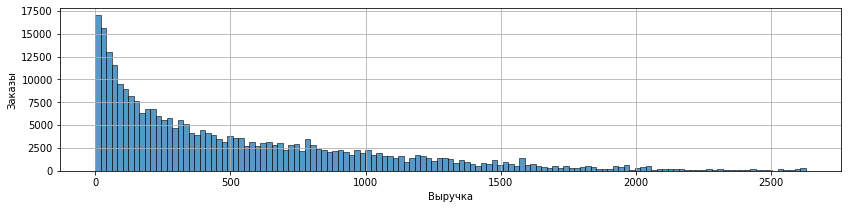

In [27]:
plt.figure(figsize=(14, 3))

sns.histplot(data=df, x='revenue_rub', kde=False)

plt.xlabel('Выручка')
plt.ylabel('Заказы')

plt.grid()
plt.show()

<AxesSubplot:ylabel='revenue_rub'>

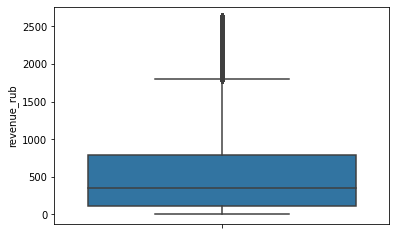

In [28]:
sns.boxplot(data=df, y='revenue_rub')

Анализируя статистические данные, можно заметить, что среднее значение (556,3) и медиана (352,08) намного ближе к минимальному значению(0), чем к максимальному(81174.54), так как выбросы находятся в правой стороне уже после 95 процентиля. Стандартное отклонение (875.8), что подтверждает разброс данных. Третий квартиль равен 802.25, значит 75% значений выручки не превышают этот показатель. Есть экстремально высокие значения, которые искажают среднее, возможно, они связаны с дорогим концертом "552398".  Для характеристики типичного размера выручки корректнее использовать медиану, а не среднее. 

Проверим распределение данных в столбце `tickets_count` и наличие выбросов. Для этого используем статистические показатели, гистограммы распределения значений или диаграммы размаха.

In [29]:
df['tickets_count'].describe()

count    287405.000000
mean          2.741323
std           1.163087
min           1.000000
25%           2.000000
50%           3.000000
75%           3.000000
max          57.000000
Name: tickets_count, dtype: float64

In [30]:
df['tickets_count'].quantile(0.99)

6.0

Построим гистограмму до 99 процентиля, чтобы увидеть основную картину без аномалий.

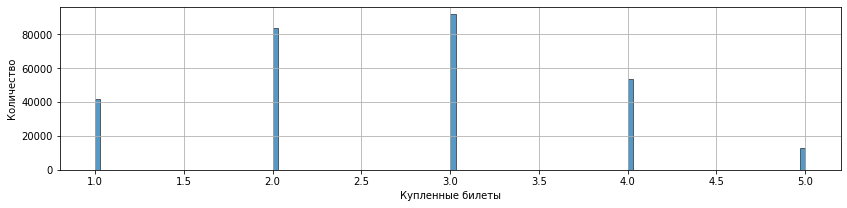

In [31]:
plt.figure(figsize=(14, 3))

sns.histplot(data=df[df['tickets_count'] < 6], x='tickets_count', kde=False)

plt.xlabel('Купленные билеты')
plt.ylabel('Количество')

plt.grid()
plt.show()

<AxesSubplot:ylabel='tickets_count'>

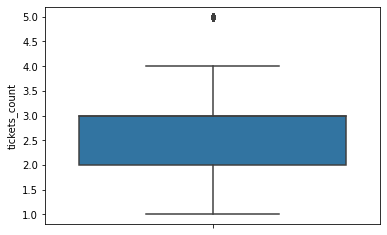

In [32]:
sns.boxplot(data=df[df['tickets_count'] < 6], y='tickets_count')

Среднее (2,74) чуть выше медианы (3) - небольшая асимметрия вправо из‑за крупных заказов (до 57 билетов). Стандартное отклонение - 1,16. 75% всех заказов - это 3 билета и меньше. Самый крупный заказ - 57 билетов, скорее всего групповая бронь.

Проверим сколько удалено строк датасета.

In [33]:
a, b = len(tmp), len(df)
display(f"Было строк в исходном датасете", a,
       "Осталось строк в датасете после обработки", b,
       "Удалено строк в датасете после обработки", a - b,
       "Процент потерь", round((a-b)/a*100, 2))

'Было строк в исходном датасете'

290611

'Осталось строк в датасете после обработки'

287405

'Удалено строк в датасете после обработки'

3206

'Процент потерь'

1.1

Промежуточный вывод:

1. По названим столбцов:
 - все столбцы уже записаны в snake_case.
 
 
2. По типам данных:
 - разрядность столбца `tickets_count` была оптимизирована.
 
 
3. По пропускам:
 - обнаружены пропуски только в столбце `days_since_prev`, которые означают, что заказ был только один.
 
 
4. Был создан новый столбец `revenue_rub`, в котором выручка приведена к единой валюте (рубли).


5. После фильтрации датасета по 99 процентилю значений выручки осталось 287405 строк, удалено 3206 строк, что равно приблизительно 1,1% от общих данных.

---

### 3. Создание профиля пользователя

В будущем отдел маркетинга планирует создать модель для прогнозирования возврата пользователей. Поэтому сейчас они просят вас построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.

---

**Задача 3.1.** Постройте профиль пользователя — для каждого пользователя найдите:

- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетного партнёра, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (используйте поле `event_type_main`);
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.

После этого добавьте два бинарных признака:

- `is_two` — совершил ли пользователь 2 и более заказа;
- `is_five` — совершил ли пользователь 5 и более заказов.

**Рекомендация:** перед тем как строить профиль, отсортируйте данные по времени совершения заказа.

---


In [34]:
df_sorted = df.sort_values('order_ts').reset_index(drop=True)

profile = df_sorted.groupby('user_id').agg(
    first_order_dt=('order_dt', 'min'),                 #дата первого заказа
    last_order_dt=('order_dt', 'max'),                  #дата последнего заказа
    total_orders=('order_id', 'nunique'),               #общее кол-во заказов
    avg_revenue_rub=('revenue_rub', 'mean'),            #средняя выручка с одного заказа в рублях
    avg_tickets=('tickets_count', 'mean'),              #среднее кол-во билетов в заказе
    first_device=('device_type_canonical', 'first'),    #устройство, с которого был сделан первый заказ
    first_region=('region_name', 'first'),              #регион, в котором был сделан первый заказ
    first_service=('service_name', 'first'),            #билетный партнёр, к которому обращались при первом заказе
    first_event_type=('event_type_main', 'first'),      #жанр первого посещённого мероприятия
    avg_days_between_orders=('days_since_prev', 'mean') #среднее время между заказами
)

profile['is_two'] = profile['total_orders'] >= 2
profile['is_five'] = profile['total_orders'] >= 5

profile = profile.reset_index()

profile.head()

,user_id,first_order_dt,last_order_dt,total_orders,avg_revenue_rub,avg_tickets,first_device,first_region,first_service,first_event_type,avg_days_between_orders,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,1,1521.940000,4.000000,mobile,Каменевский регион,Край билетов,театр,NaN,False,False
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,2,774.010000,3.000000,mobile,Каменевский регион,Мой билет,выставки,75.0,True,False
2,000898990054619,2024-07-13,2024-10-23,3,767.213333,2.666667,mobile,Североярская область,Лови билет!,другое,51.0,True,False
3,00096d1f542ab2b,2024-08-15,2024-08-15,1,917.830000,4.000000,desktop,Каменевский регион,Край билетов,театр,NaN,False,False
4,000a55a418c128c,2024-09-29,2024-10-15,2,61.310000,1.500000,mobile,Поленовский край,Лучшие билеты,театр,16.0,True,False


---

**Задача 3.2.** Прежде чем проводить исследовательский анализ данных и делать выводы, важно понять, с какими данными вы работаете: насколько они репрезентативны и нет ли в них аномалий.

Используя данные о профилях пользователей, рассчитайте:

- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа;
- долю пользователей, совершивших 5 и более заказов.

Также изучите статистические показатели:

- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.

По результатам оцените данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов?

Если вы найдёте аномальные значения, опишите их и примите обоснованное решение о том, как с ними поступить:

- Оставить и учитывать их при анализе?
- Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?

Если вы проведёте фильтрацию, то вычислите объём отфильтрованных данных и выведите статистические показатели по обновлённому датасету.

- Так как датасет формировался с помощью группировки, каждая строка - это уникальный пользователь.

In [35]:
f'Общее количество пользователей в выборке - {len(profile)}'

'Общее количество пользователей в выборке - 21838'

In [36]:
display(f"Средняя выручка с одного заказа: {round(profile['avg_revenue_rub'].mean(), 3)}")

share_is_two = profile['is_two'].mean()
display(f'Доля пользователей, совершивших 2 и более заказа: {round(share_is_two, 3)}')

share_is_five = profile['is_five'].mean()
f'Доля пользователей, совершивших 5 и более заказа: {round(share_is_five, 3)}'

'Средняя выручка с одного заказа: 545.033'

'Доля пользователей, совершивших 2 и более заказа: 0.617'

'Доля пользователей, совершивших 5 и более заказа: 0.29'

- Посмотрим статистические показатели по общему числу заказов:

In [37]:
profile['total_orders'].describe()

count    21838.000000
mean        13.160775
std        121.577370
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max      10168.000000
Name: total_orders, dtype: float64

- Общее число пользователей - 21838. Минимальное количество заказов 1, а максимальное - 10168, при этом медиана - 2, 50% пользователей делают только 2 заказа. Огромное стандартное отклонение (121,57) говорит о большом разбросе даннных. 


- Отфильтруем датасет по 95 процентилю, чтобы отсеять корпоративных клиентов и увидеть распределение без аномалий.

In [38]:
procentil_95 = profile['total_orders'].quantile(0.95)
profile_normal = profile[profile['total_orders'] <= procentil_95].copy()

display("До фильтрации:", len(profile))
display("После (до 95-го перцентиля):", len(profile_normal))
display("Отсеяно пользователей:", len(profile) - len(profile_normal))

'До фильтрации:'

21838

'После (до 95-го перцентиля):'

20747

'Отсеяно пользователей:'

1091

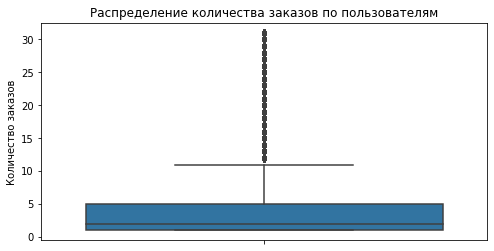

In [39]:
plt.figure(figsize=(8, 4))

sns.boxplot(y=profile_normal['total_orders'])

plt.title('Распределение количества заказов по пользователям')
plt.ylabel('Количество заказов')
plt.show()

In [40]:
profile_normal['total_orders'].describe()

count    20747.000000
mean         4.049164
std          5.113877
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max         31.000000
Name: total_orders, dtype: float64

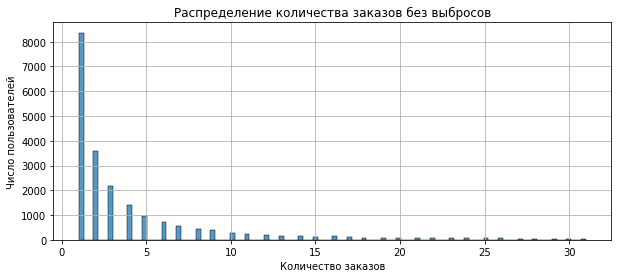

In [41]:
plt.figure(figsize=(10, 4))

sns.histplot(data=profile_normal, x='total_orders', kde=False)

plt.title('Распределение количества заказов без выбросов')
plt.xlabel('Количество заказов')
plt.ylabel('Число пользователей')

plt.grid()
plt.show()

- После исключения пользователей с большими закупками среднее количество заказов на пользователя составило 4,05 при медиане 2. Это означает, что половина делает не более 2 заказов, большинство (75%) - не более 5.

- Посмотрим статистические показатели по среднему числу билетов в заказе:

In [42]:
profile_normal['avg_tickets'].describe()

count    20747.000000
mean         2.744537
std          0.934517
min          1.000000
25%          2.000000
50%          2.750000
75%          3.153846
max         11.000000
Name: avg_tickets, dtype: float64

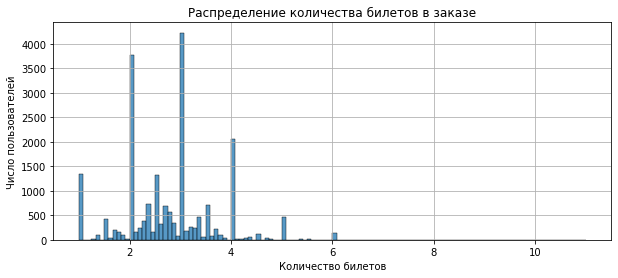

In [43]:
plt.figure(figsize=(10, 4))

sns.histplot(data=profile_normal, x='avg_tickets', kde=False)

plt.title('Распределение количества билетов в заказе')
plt.xlabel('Количество билетов')
plt.ylabel('Число пользователей')

plt.grid()
plt.show()

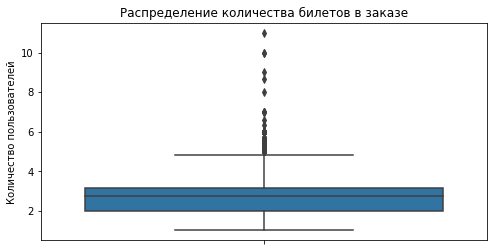

In [44]:
plt.figure(figsize=(8, 4))

sns.boxplot(y=profile_normal['avg_tickets'])

plt.title('Распределение количества билетов в заказе')
plt.ylabel('Количество пользователей')
plt.show()

- Среднее количество билетов в заказе не показывает экстремальных значений. Минимальное значение - 1, максимальное - 11. Среднее значение и медиана почти сравнялись (~2,7). 75% пользователей покупают не больше 3 билетов.

- Посмотрим статистические показатели по среднему количеству дней между покупками.

In [45]:
profile_normal['avg_days_between_orders'].describe()

count    12420.000000
mean        17.049496
std         22.872397
min          0.000000
25%          1.000000
50%          9.464103
75%         22.000000
max        148.000000
Name: avg_days_between_orders, dtype: float64

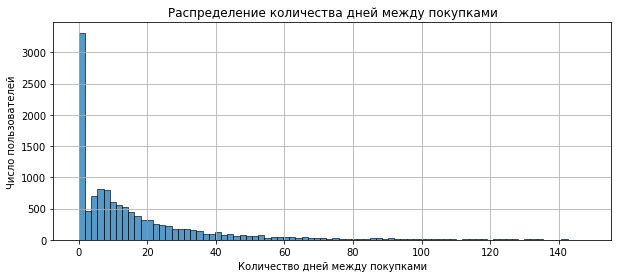

In [46]:
plt.figure(figsize=(10, 4))

sns.histplot(data=profile_normal, x='avg_days_between_orders', kde=False)

plt.title('Распределение количества дней между покупками')
plt.xlabel('Количество дней между покупками')
plt.ylabel('Число пользователей')

plt.grid()
plt.show()

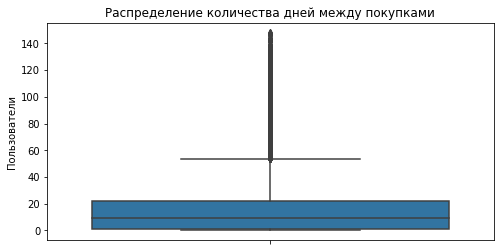

In [47]:
plt.figure(figsize=(8, 4))

sns.boxplot(y=profile_normal['avg_days_between_orders'])

plt.title('Распределение количества дней между покупками')
plt.ylabel('Пользователи')
plt.show()

- Сильный перекос и большой разброс: среднее (17,05) заметно выше медианы (9,46), а стандартное отклонение (22,8). Значит, есть много пользователей с очень длинными перерывами между заказами.

Вывод:

1. Используя данные о профилях пользователей, рассчитали общее число пользователей в выборке (21838), среднюю выручку с одного заказа (545.033), долю пользователей, совершивших 2 и более заказа (0.617) и долю пользователей, совершивших 5 и более заказов (0,29)

2. После анализа статистических значений количества купленных билетов отфильтровали датасет по 95 процентилю, чтобы отсеять корпоративных клиентов и увидеть распределение без аномалий. 

 - размер до фильтрации: 21838
 - после (до 95-го перцентиля): 20747
 - отсеяно пользователей: 1091, что составляет 5% от данных.

3. После исключения пользователей с большими закупками среднее количество заказов на пользователя составило 4,05 при медиане 2. Это означает, что половина делает не более 2 заказов, большинство (75%) - не более 5.

4. Среднее количество билетов в заказе не показывает экстремальных значений. Минимальное значение - 1, максимальное - 11. Среднее значение и медиана почти сравнялись (~2,7). 75% пользователей покупают 3 билета.

5. При анализе среднего количества дней между покупками обнаружили сильный перекос и большой разброс: среднее (17,05) заметно выше медианы (9,46), а стандартное отклонение (22,8). Значит, есть много пользователей с очень длинными перерывами между заказами.

---

### 4. Исследовательский анализ данных

Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа. Для этого используйте профили пользователей.



#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

---

**Задача 4.1.1.** Изучите распределение пользователей по признакам.

- Сгруппируйте пользователей:
    - по типу их первого мероприятия;
    - по типу устройства, с которого совершена первая покупка;
    - по региону проведения мероприятия из первого заказа;
    - по билетному оператору, продавшему билеты на первый заказ.
- Подсчитайте общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Сегмент — это группа пользователей, объединённых определённым признаком, то есть объединённые принадлежностью к категории. Например, все клиенты, сделавшие первый заказ с мобильного телефона, — это сегмент.
- Ответьте на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?

---


- Сгруппируем пользователей по типу их первого мероприятия.

In [48]:
total_users = len(profile_normal)

segment_event = profile_normal.groupby('first_event_type').agg(
    users_count=('user_id', 'count')).sort_values('users_count', ascending=False).reset_index()
segment_event['share'] = (segment_event['users_count'] / total_users * 100).round(2)

segment_event

,first_event_type,users_count,share
0,концерты,9191,44.30
1,другое,5157,24.86
2,театр,4070,19.62
3,стендап,1069,5.15
4,спорт,765,3.69
5,выставки,401,1.93
6,ёлки,94,0.45


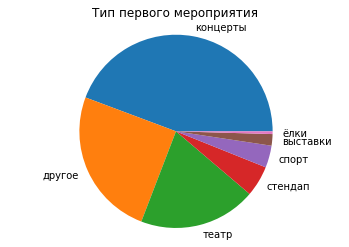

In [49]:
plt.pie(segment_event['share'], labels=segment_event['first_event_type'])

plt.title('Тип первого мероприятия')
plt.axis('equal')

plt.show()

- Сгруппируем пользователей по типу устройства, с которого совершена первая покупка.

In [50]:
segment_device = profile_normal.groupby('first_device').agg(
    users_count=('user_id', 'count')).sort_values('users_count', ascending=False).reset_index()
segment_device['share'] = (segment_device['users_count'] / total_users * 100).round(2)

segment_device

,first_device,users_count,share
0,mobile,17208,82.94
1,desktop,3539,17.06


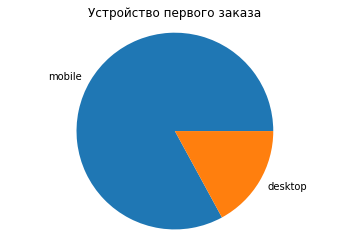

In [51]:
plt.pie(segment_device['share'], labels=segment_device['first_device'])

plt.title('Устройство первого заказа')
plt.axis('equal')

plt.show()

- Сгруппируем пользователей по региону проведения мероприятия из первого заказа.

In [52]:
segment_region = profile_normal.groupby('first_region').agg(
    users_count=('user_id', 'count')).sort_values('users_count', ascending=False).reset_index()
segment_region['share'] = (segment_region['users_count'] / total_users * 100).round(2)

segment_region

,first_region,users_count,share
0,Каменевский регион,6781,32.68
1,Североярская область,3599,17.35
2,Широковская область,1183,5.70
3,Озернинский край,660,3.18
4,Малиновоярский округ,516,2.49
...,...,...,...
76,Залесский край,2,0.01
77,Верхозёрский край,1,0.00
78,Светолесский край,1,0.00
79,Сосноводолинская область,1,0.00


- Сгруппируем пользователей по билетному оператору, продавшему билеты на первый заказ.

In [53]:
segment_service = profile_normal.groupby('first_service').agg(
    users_count=('user_id', 'count')).sort_values('users_count', ascending=False).reset_index()
segment_service['share'] = (segment_service['users_count'] / total_users * 100).round(2)

segment_service

,first_service,users_count,share
0,Билеты без проблем,4958,23.90
1,Мой билет,2853,13.75
2,Лови билет!,2707,13.05
3,Билеты в руки,2423,11.68
4,Облачко,2108,10.16
5,Весь в билетах,1234,5.95
6,Лучшие билеты,1130,5.45
7,Прачечная,550,2.65
8,Край билетов,438,2.11
9,Дом культуры,340,1.64


Распределение неравномерное - есть ярко выраженные «точки входа», а остальные сегменты заметно уступают по доле. 

1. Распределение пользователей по типу первого мероприятия: доминирующей точкой входа является сегмент “Концерты” (44,3%), на который приходится почти половина новых пользователей. В совокупности сегменты “Концерты” и “Другое” охватывают 69,2% аудитории. Остальные категории (театр, стендап, спорт и др.) имеют существенно меньшую долю.

2. Распределение пользователей по типу устройства первого заказа сильно смещено в сторону мобильных устройств: 83% пользователей совершают первую покупку с телефона. Доля десктопа составляет 17%.

3. Распределение пользователей по региону первого заказа сильно неравномерное: два региона (Каменевский - 32,7% и Североярская область - 17,3%) охватывают 50% всей аудитории. Остальные регионы имеют существенно меньшую долю.

4. Распределение пользователей по билетному оператору первого заказа такэе является неравномерным: топ‑5 операторов («Билеты без проблем», «Мой билет», «Лови билет!», «Билеты в руки», «Облачко») в совокупности охватывают 72,5% аудитории, при этом доля лидера составляет ~24%.

---

**Задача 4.1.2.** Проанализируйте возвраты пользователей:

- Для каждого сегмента вычислите долю пользователей, совершивших два и более заказа.
- Визуализируйте результат подходящим графиком. Если сегментов слишком много, то поместите на график только 10 сегментов с наибольшим количеством пользователей. Такое возможно с сегментами по региону и по билетному оператору.
- Ответьте на вопросы:
    - Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
    - Наблюдаются ли успешные «точки входа» - такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?

При интерпретации результатов учитывайте размер сегментов: если в сегменте мало пользователей (например, десятки), то доли могут быть нестабильными и недостоверными, то есть показывать широкую вариацию значений.

---


Изучим, существует ли зависимость между возвращением пользователя к покупке билетов и жанром мероприятия в первое посещение. Для этого построим столбчатую диаграмму с разделение по признаку `is_two` среди разных жанров. 

Рассчитаем среднее значение с помощью profile_normal.groupby('first_event_type')['is_two'] и визуализируем результат с помощью столбчатой диаграммы.

In [54]:
grouped = profile_normal.groupby('first_event_type')['is_two'].mean().sort_values()
grouped

first_event_type
спорт       0.541176
ёлки        0.553191
другое      0.576498
стендап     0.594013
концерты    0.602655
театр       0.618673
выставки    0.630923
Name: is_two, dtype: float64

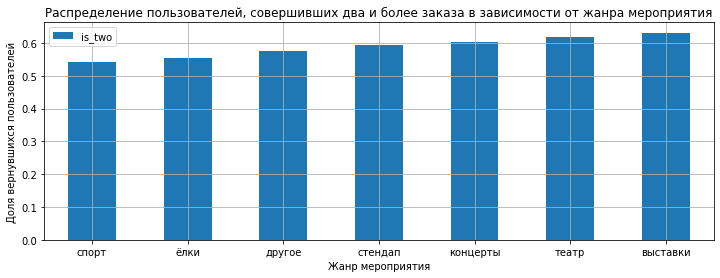

In [55]:
grouped.plot(kind='bar',
            title=f'Распределение пользователей, совершивших два и более заказа в зависимости от жанра мероприятия',
            legend=True,
            ylabel='Доля вернувшихся пользователей',
            xlabel='Жанр мероприятия',
            rot=0,
            figsize=(12,4))
plt.grid()
plt.show()

Видно, что доля вернувшихся пользователей практически не отличается в зависимости от жанра первого посещенного мероприятия. Разница небольшая - от 0,54 (спорт) до 0,63 (выставки).

Посмотрим на доли в разрезе типа устройства, с которого совершена первая покупка.

In [56]:
grouped = profile_normal.groupby('first_device')['is_two'].mean().sort_values()
grouped

first_device
mobile     0.592108
desktop    0.620232
Name: is_two, dtype: float64

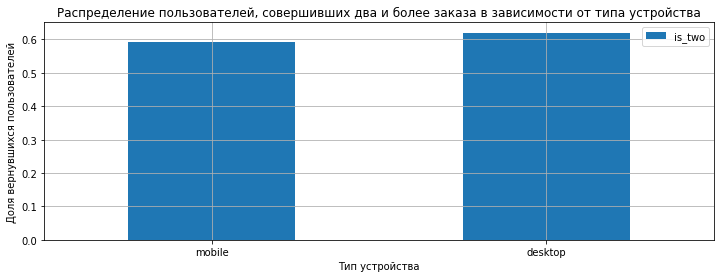

In [57]:
grouped.plot(kind='bar',
            title=f'Распределение пользователей, совершивших два и более заказа в зависимости от типа устройства',
            legend=True,
            ylabel='Доля вернувшихся пользователей',
            xlabel='Тип устройства',
            rot=0,
            figsize=(12,4))
plt.grid()
plt.show()

Здесь тоже доля почти не отличается в зависимости от типа устройства в первое посещение - 0,59 (mobile) и 0,62 (desctop).

Следующим проанализируем регион первого заказа.

In [58]:
grouped = profile_normal.groupby('first_region')['is_two'].mean().sort_values(ascending=False)
grouped = grouped.head(10)
grouped

first_region
Верхозёрский край         1.000000
Озернопольская область    0.888889
Радужнопольский край      0.761905
Лесостепной край          0.690909
Тихолесский край          0.666667
Лесноярский край          0.666667
Горноземский регион       0.653846
Ягодиновская область      0.650000
Шанырский регион          0.645788
Горицветская область      0.643478
Name: is_two, dtype: float64

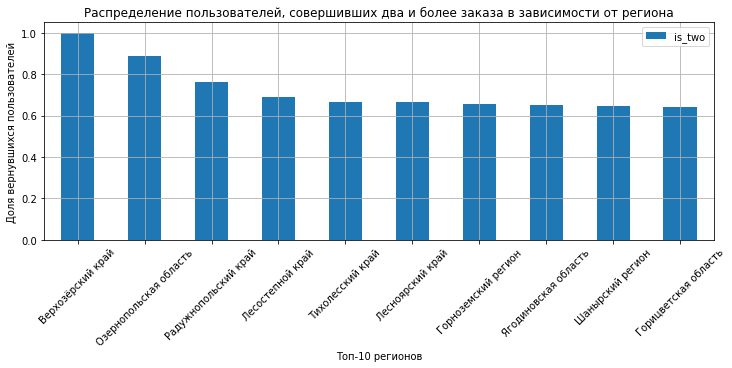

In [59]:
grouped.plot(kind='bar',
            title=f'Распределение пользователей, совершивших два и более заказа в зависимости от региона',
            legend=True,
            ylabel='Доля вернувшихся пользователей',
            xlabel='Топ-10 регионов',
            rot=45,
            figsize=(12,4))
plt.grid()
plt.show()

Здесь уже виден лидер - Верхозёрский край, тут 100% пользователей вернулись к заказам билетов. Озернопольская область - 88%, Радужнопольский край - 76%.

Осталось проанализировать билетных партнеров, к которым обращались при первом заказе.

In [60]:
grouped = profile_normal.groupby('first_service')['is_two'].mean().sort_values(ascending=False)
grouped = grouped.head(10)
grouped

first_service
Зе Бест!             1.000000
Быстрый кассир       0.836364
Билет по телефону    0.833333
Реестр               0.777778
Восьмёрка            0.670732
Crazy ticket!        0.666667
Росбилет             0.650000
Show_ticket          0.642857
Край билетов         0.639269
Дом культуры         0.629412
Name: is_two, dtype: float64

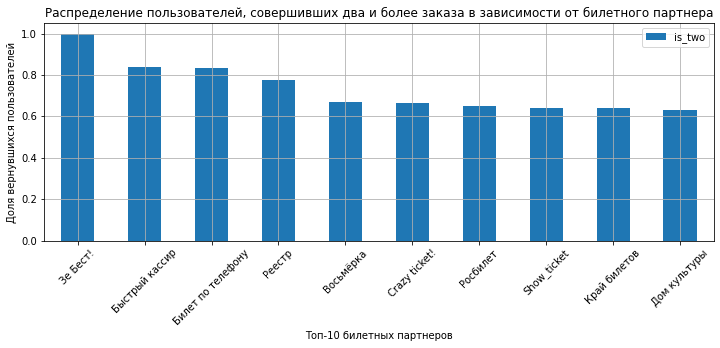

In [61]:
grouped.plot(kind='bar',
            title=f'Распределение пользователей, совершивших два и более заказа в зависимости от билетного партнера',
            legend=True,
            ylabel='Доля вернувшихся пользователей',
            xlabel='Топ-10 билетных партнеров',
            rot=45,
            figsize=(12,4))
plt.grid()
plt.show()

Тут тоже есть лидер - Зе Бест!, 100% пользователей вернулись к заказам билетов. При этом нужно смотреть на количество проданных билетов, потому что у Зе Беста всего один проданный билет. Быстрый кассир и Билет по телефону - по 83%, замыкает десятку Дом культуры - 63%.

---

**Задача 4.1.3.** Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:

- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

---

Гипотеза 1 не подтвердилась. В ходе проделанного анализа выяснили, что доля вернувшихся пользователей практически не отличается в зависимости от жанра первого посещенного мероприятия. У спортивных мероприятий вероятность самая маленькая (0,54), у выставок - самая высокая (0,63).

Гипотеза 2. Для того, чтобы утверждать или опровергать эту гипотезу, нужно знать активные регионы. Доля посчитана, и среди регионов в лидерах - Верхозёрский край, Озернопольская область, Радужнопольский край, Лесостепной край, Тихолесский край, Лесноярский край, Горноземский регион, Ягодиновская область, Шанырский регион, Горицветская область. 

Теперь стоит посчитать регионы, где больше всего пользователй посещают мероприятия.

In [62]:
region_activity = (df.groupby('region_name')['user_id']
    .nunique().reset_index().rename(columns={'user_id': 'unique_users'}))

region_activity.sort_values('unique_users', ascending=False)

,region_name,unique_users
23,Каменевский регион,10556
60,Североярская область,6692
77,Широковская область,3245
45,Озернинский край,2472
41,Малиновоярский округ,1873
...,...,...
80,Яснопольский округ,11
33,Лесноярский край,10
66,Сосноводолинская область,7
68,Теплоозёрский округ,5


После подсчета наиболее активных регионов, мы увидели, что гипотеза не подтвердилась, регионы не совпали.

---

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

Изучите количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

Эти метрики важны не только для оценки выручки, но и для оценки вовлечённости пользователей. Возможно, пользователи с более крупными и дорогими заказами более заинтересованы в сервисе и поэтому чаще возвращаются.

---

**Задача 4.2.1.** Проследите связь между средней выручкой сервиса с заказа и повторными заказами.

- Постройте сравнительные гистограммы распределения средней выручки с билета (`avg_revenue_rub`):
    - для пользователей, совершивших один заказ;
    - для вернувшихся пользователей, совершивших 2 и более заказа.
- Ответьте на вопросы:
    - В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
    - Есть ли различия между группами?

Текст на сером фоне:
    
**Рекомендация:**

1. Используйте одинаковые интервалы (`bins`) и прозрачность (`alpha`), чтобы визуально сопоставить распределения.
2. Задайте параметру `density` значение `True`, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается.

---


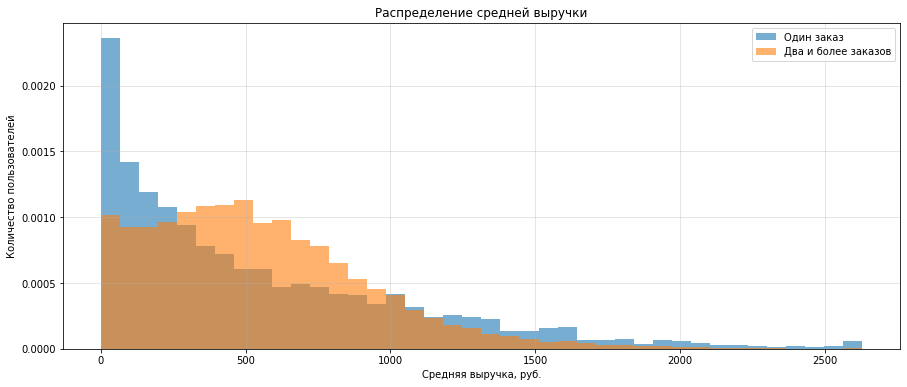

In [63]:
one_order = profile_normal[(profile_normal['is_two'] == False) & (profile_normal['is_five'] == False)]['avg_revenue_rub']
two_orders = profile_normal[profile_normal['is_two'] == 1]['avg_revenue_rub']

plt.figure(figsize=(15, 6))

plt.hist(one_order, bins=40, alpha=0.6, label='Один заказ', density=True)
plt.hist(two_orders, bins=40, alpha=0.6, label='Два и более заказов', density=True)

plt.xlabel('Средняя выручка, руб.')
plt.ylabel('Количество пользователей')
plt.title('Распределение средней выручки')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

На графике видно, что распределение средней выручки пользователей с одним заказом сдвинуто вправую область, столбцы постепенно уменьшаются по высоте слева направо, пик средней выручки находится от 0 до 75. В то время как средняя выручка пользователей с двумя и более заказами также уменьшаются, но менее заметно. Нет экстремального пика, а основная масса значений лежит в диапазоне 200–800 рублей. 

Можно охарактеризовать распределение как две модели поведения. Пользователи с одним заказом часто покупают самые дешевые билеты и очень редко дорогие. У пользователей с 2 и более заками чаще выбирают среднюю стоимость билетов, не гонятся за самыми дешевыми и эксклюзивными дорогими.

---

**Задача 4.2.2.** Сравните распределение по средней выручке с заказа в двух группах пользователей:

- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

Ответьте на вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?

---


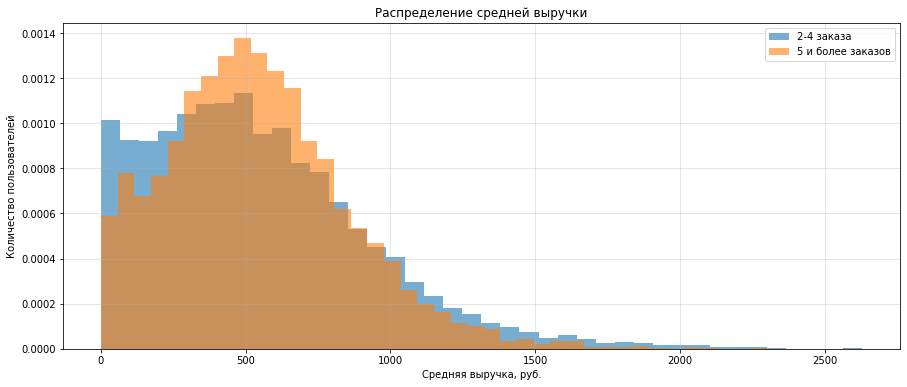

In [64]:
two_orders = profile_normal[profile_normal['is_two'] == True]['avg_revenue_rub']
five_orders = profile_normal[profile_normal['is_five'] == True]['avg_revenue_rub']

plt.figure(figsize=(15, 6))

plt.hist(two_orders, bins=40, alpha=0.6, label='2-4 заказa', density=True)
plt.hist(five_orders, bins=40, alpha=0.6, label='5 и более заказов', density=True)

plt.xlabel('Средняя выручка, руб.')
plt.ylabel('Количество пользователей')
plt.title('Распределение средней выручки')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

Пик обоих гистограмм приходятся примерно на 400-600 рублей. Только у пользователей с 5 и более заказами пик выше, т.к. больше пользователей покупают билеты этой ценовой категории. У оранжевой гистограммы частота минимальных значений ниже, чем у синей, значит пользователи с 2-4 заказами чаще покупают дешевые билеты. Хвост у обеих гистограмм сильно уменьшается после 1000 рублей, но у самых постоянных пользователей он еще тоньше, чем у пользователей с 2-4 заказами. 

---

**Задача 4.2.3.** Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки.

- Изучите распределение пользователей по среднему количеству билетов в заказе (`avg_tickets_count`) и опишите основные наблюдения.
- Разделите пользователей на несколько сегментов по среднему количеству билетов в заказе:
    - от 1 до 2 билетов;
    - от 2 до 3 билетов;
    - от 3 до 5 билетов;
    - от 5 и более билетов.
- Для каждого сегмента подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы.
- Ответьте на вопросы:
    - Как распределены пользователи по сегментам — равномерно или сконцентрировано?
    - Есть ли сегменты с аномально высокой или низкой долей повторных покупок?

---

In [65]:
def categorize(tickets):
    if 1 <= tickets < 2:
        return '1–2 билета'
    elif 2 <= tickets < 3:
        return '2–3 билета'
    elif 3 <= tickets < 5:
        return '3–5 билетов'
    elif tickets >= 5:
        return '5 и более билетов'
    else:
        return 'Не определено'
    
profile_normal['cat_avg_tickets'] = profile_normal['avg_tickets'].apply(categorize)
profile_normal.head()

,user_id,first_order_dt,last_order_dt,total_orders,avg_revenue_rub,avg_tickets,first_device,first_region,first_service,first_event_type,avg_days_between_orders,is_two,is_five,cat_avg_tickets
0,0002849b70a3ce2,2024-08-20,2024-08-20,1,1521.940000,4.000000,mobile,Каменевский регион,Край билетов,театр,NaN,False,False,3–5 билетов
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,2,774.010000,3.000000,mobile,Каменевский регион,Мой билет,выставки,75.0,True,False,3–5 билетов
2,000898990054619,2024-07-13,2024-10-23,3,767.213333,2.666667,mobile,Североярская область,Лови билет!,другое,51.0,True,False,2–3 билета
3,00096d1f542ab2b,2024-08-15,2024-08-15,1,917.830000,4.000000,desktop,Каменевский регион,Край билетов,театр,NaN,False,False,3–5 билетов
4,000a55a418c128c,2024-09-29,2024-10-15,2,61.310000,1.500000,mobile,Поленовский край,Лучшие билеты,театр,16.0,True,False,1–2 билета


In [66]:
grouped_data = profile_normal.groupby('cat_avg_tickets', as_index=False).agg(
    count=('user_id', 'count'), repeat=('is_two', 'sum'))    
        
grouped_data['share'] = (grouped_data['repeat'] / grouped_data['count']).round(3)
grouped_data

,cat_avg_tickets,count,repeat,share
0,1–2 билета,2406,1231,0.512
1,2–3 билета,8752,6244,0.713
2,3–5 билетов,8928,4785,0.536
3,5 и более билетов,661,124,0.188


Самая многочисленная категория - "3-5 билетов" (8928 пользователей), при этом вернулось чуть больше половины (4785). Лидер по доле пользователей, совершивших повторные заказы - категория "2-3 билета" - 6244 из 8752 пользователей вернулись. В категории "1-2 билета" 2406 пользователей, из них возвращаются половина. Слабее всего представлена категория "5 и более билетов" - всего 661 пользователь, и только 18,8% из них делают повторные заказы.

---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучите временные параметры, связанные с первым заказом пользователей:

- день недели первой покупки;
- время с момента первой покупки — лайфтайм;
- средний интервал между покупками пользователей с повторными заказами.

---

**Задача 4.3.1.** Проанализируйте, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

- По данным даты первого заказа выделите день недели.
- Для каждого дня недели подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
- Ответьте на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

---


In [67]:
profile_normal['day_of_week'] = profile_normal['first_order_dt'].dt.strftime('%a')

In [68]:
grouped_data = profile_normal.groupby('day_of_week', as_index=False).agg(
    count=('user_id', 'count'), repeat=('is_two', 'sum'))  
        
grouped_data['share'] = (grouped_data['repeat'] / grouped_data['count']).round(3)
grouped_data = grouped_data.sort_values(by='share', ascending=False)
grouped_data

,day_of_week,count,repeat,share
1,Mon,2813,1733,0.616
6,Wed,2960,1805,0.610
2,Sat,3120,1883,0.604
5,Tue,3024,1814,0.600
0,Fri,3163,1853,0.586
4,Thu,3026,1764,0.583
3,Sun,2641,1532,0.580


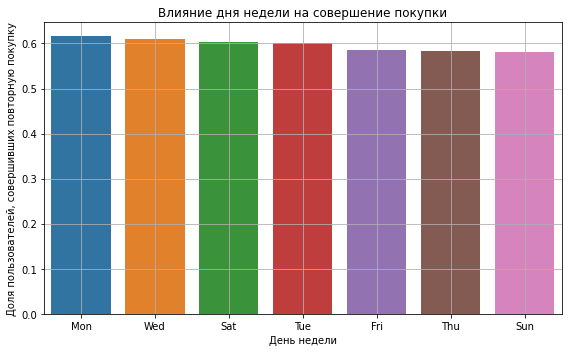

In [69]:
plt.figure(figsize=(8, 5))

sns.barplot(data=grouped_data,
           x=grouped_data['day_of_week'],
           y=grouped_data['share'])

plt.title('Влияние дня недели на совершение покупки')
plt.xlabel('День недели')
plt.ylabel('Доля пользователей, совершивших повторную покупку')

plt.grid()
plt.tight_layout()
plt.show()

Доля повторных заказов почти не зависит от дня первого заказа. Максимум - в понедельник (61%), минимум - в воскресенье (58%).

---

**Задача 4.3.2.** Изучите, как средний интервал между заказами влияет на удержание клиентов.

- Рассчитайте среднее время между заказами для двух групп пользователей:
    - совершившие 2–4 заказа;
    - совершившие 5 и более заказов.
- Исследуйте, как средний интервал между заказами влияет на вероятность повторного заказа, и сделайте выводы.

---


In [70]:
is_2_4 = profile_normal[(profile_normal['is_two'] == True) & 
    (profile_normal['is_five'] == False)]['avg_days_between_orders'].mean()
f'Среднее время между заказами для группы 2-4 заказа: {is_2_4.round(3)} дней'

'Среднее время между заказами для группы 2-4 заказа: 21.329 дней'

In [71]:
is_5 = profile_normal[profile_normal['is_five'] == True]['avg_days_between_orders'].mean()
f'Среднее время между заказами для группы 5 и более заказов: {is_5.round(3)} дней'

'Среднее время между заказами для группы 5 и более заказов: 11.13 дней'

Чем больше заказов сделал пользователь, тем чаще он возвращается. Значит можно судить о растущей лояльности пользователя по уменьшению интервала между заказами.

---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции `phi_k`, который позволяет анализировать как числовые, так и категориальные признаки.

---

**Задача 4.4.1:** Проведите корреляционный анализ:
- Рассчитайте коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов (`total_orders`). При необходимости используйте параметр `interval_cols` для определения интервальных данных.
- Проанализируйте полученные результаты. Если полученные значения будут близки к нулю, проверьте разброс данных в `total_orders`. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделите сегменты пользователей по полю `total_orders`, а затем повторите корреляционный анализ. Выделите такие сегменты:
    - 1 заказ;
    - от 2 до 4 заказов;
    - от 5 и выше.
- Визуализируйте результат корреляции с помощью тепловой карты.
- Ответьте на вопрос: какие признаки наиболее связаны с количеством заказов?

---

In [72]:
cols_for_phik = profile_normal.drop(columns=['user_id'])

interval_cols = ['total_orders', 'avg_days_between_orders', 'avg_revenue_rub', 'avg_tickets']

correl_matrix = cols_for_phik.phik_matrix(interval_cols=interval_cols)

correl_matrix['total_orders'].sort_values(ascending=False)

total_orders               1.000000
is_five                    0.986309
is_two                     0.720337
avg_days_between_orders    0.489516
first_order_dt             0.399006
last_order_dt              0.398842
avg_tickets                0.296849
avg_revenue_rub            0.263569
cat_avg_tickets            0.242197
first_device               0.049654
first_service              0.038188
first_event_type           0.034018
first_region               0.019898
day_of_week                0.019044
Name: total_orders, dtype: float64

Проанализировав коэффициент корреляции phi_k между признаками профиля пользователя и числом заказов можно выделить:

    - наибольшая корреляция с признаком is_five и is_two, которые являются флагами повторной покупки. Это логичная зависимость.
    
    - avg_days_between_orders, first_order_dt и last_order_dt содержат информацию о днях между покупками, а так же дате первой и последней покупке. 
    
    - avg_tickets - среднее количество билетов, avg_revenue_rub - средняя выручка, cat_avg_tickets - категория по количеству билетов в заказе показывают сравнительно одинаковую корреляцию (~ 0,26) 
    
    - остальные номинальные значения практически не показывают корреляции с количеством заказов.

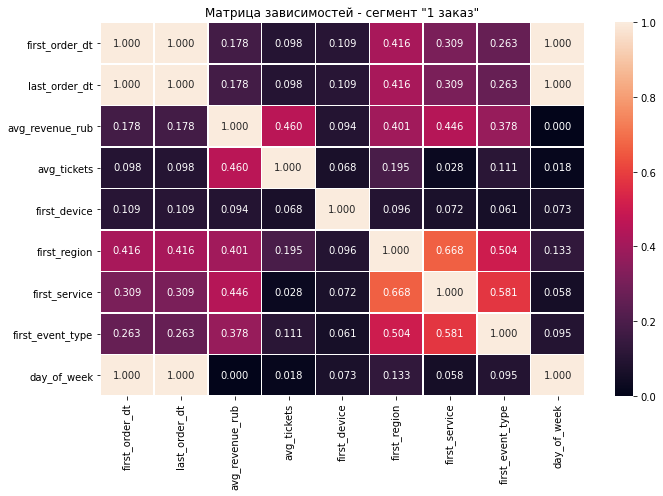

In [73]:
interval_cols_base = ['avg_revenue_rub', 'avg_tickets', 'avg_days_between_orders']

seg1 = profile_normal[profile_normal['total_orders'] == 1].copy()
data1 = seg1.drop(columns=['user_id', 'total_orders', 'is_two', 'is_five', 'avg_days_between_orders', 'cat_avg_tickets'])

matrix1 = data1.phik_matrix(interval_cols=['avg_revenue_rub', 'avg_tickets'])

plt.figure(figsize=(10, 7))
sns.heatmap(
    matrix1,
    annot=True,
    fmt='.3f',
    linewidths=0.5)

plt.title('Матрица зависимостей - сегмент "1 заказ"')
plt.tight_layout()
plt.show()

В сегменте "1 заказ" умеренную связь показывают `first_region` и `first_service` (0,668). Первый регион и первый жанр мероприятия также показывают умеренную корреляцию (0,504). 
Средняя выручка и количество билетов, что логично, коррелируют с коэффициентом (0,46). Выручка с регионом немного сильнее - 0,446.

In [74]:
seg2 = profile_normal[(profile_normal['total_orders'] >= 2) & (profile_normal['total_orders'] <= 4)].copy()
data2 = seg2.drop(columns=['user_id', 'is_two', 'is_five', 'cat_avg_tickets'])
matrix2 = data2.phik_matrix(interval_cols=['avg_revenue_rub', 'avg_tickets', 'avg_days_between_orders', 'total_orders'])

matrix2['total_orders'].sort_values(ascending=False)

total_orders               1.000000
avg_days_between_orders    0.385079
avg_tickets                0.369235
first_order_dt             0.230673
last_order_dt              0.165532
avg_revenue_rub            0.108652
first_service              0.062915
first_device               0.009511
first_region               0.000000
first_event_type           0.000000
day_of_week                0.000000
Name: total_orders, dtype: float64

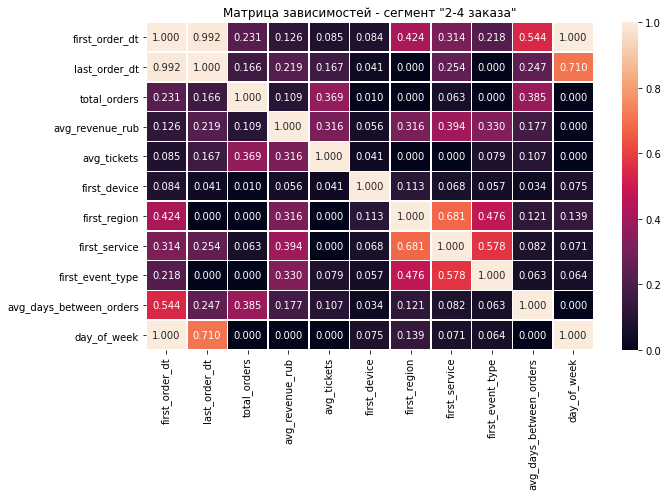

In [75]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    matrix2,
    annot=True,
    fmt='.3f',
    linewidths=0.5)

plt.title('Матрица зависимостей - сегмент "2-4 заказa"')
plt.tight_layout()
plt.show()

Основная связь `total_orders` с `avg_days_between_orders` (0,385) и `avg_tickets` (0,369). Умеренная связь с `first_order_dt` (0,231), `last_order_dt` (0,166).
Слабое влияние: выручка, регион, тип события, день недели. 

In [76]:
seg3 = profile_normal[profile_normal['total_orders'] >= 5].copy()
data3 = seg3.drop(columns=['user_id', 'is_two', 'is_five', 'cat_avg_tickets'])
data3 = data3.loc[:, data3.nunique() > 1]
matrix3 = data3.phik_matrix(interval_cols=['avg_revenue_rub', 'avg_tickets', 'avg_days_between_orders', 'total_orders'])

matrix3['total_orders'].sort_values(ascending=False)

total_orders               1.000000
avg_days_between_orders    0.712580
first_order_dt             0.191245
avg_revenue_rub            0.167214
avg_tickets                0.119224
first_region               0.071363
last_order_dt              0.068115
first_service              0.065326
first_event_type           0.054858
first_device               0.038473
day_of_week                0.000000
Name: total_orders, dtype: float64

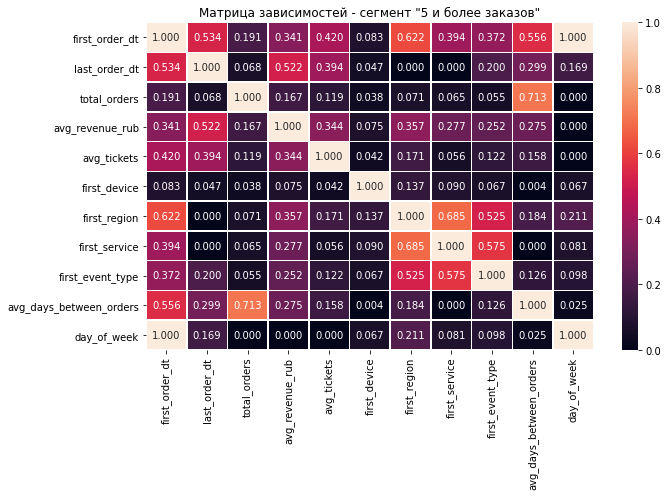

In [77]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    matrix3,
    annot=True,
    fmt='.3f',
    linewidths=0.5)

plt.title('Матрица зависимостей - сегмент "5 и более заказов"')
plt.tight_layout()
plt.show()

Основная связь с `avg_days_between_orders` (0,713).
Умеренная с `first_order_dt` (0,191), `avg_revenue_rub` (0,167), `cat_avg_tickets` (0,137), `avg_tickets` (0,119).
Остальные связи слабые.
`day_of_week` совсем не коррелирует с `total_orders`.

### 5. Общий вывод и рекомендации

В конце проекта напишите общий вывод и рекомендации: расскажите заказчику, на что нужно обратить внимание. В выводах кратко укажите:

- **Информацию о данных**, с которыми вы работали, и то, как они были подготовлены: например, расскажите о фильтрации данных, переводе тенге в рубли, фильтрации выбросов.
- **Основные результаты анализа.** Например, укажите:
    - Сколько пользователей в выборке? Как распределены пользователи по числу заказов? Какие ещё статистические показатели вы подсчитали важным во время изучения данных?
    - Какие признаки первого заказа связаны с возвратом пользователей?
    - Как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок?
    - Какие временные характеристики влияют на удержание (день недели, интервалы между покупками)?
    - Какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок согласно результатам корреляционного анализа?
- Дополните выводы информацией, которая покажется вам важной и интересной. Следите за общим объёмом выводов — они должны быть компактными и ёмкими.

В конце предложите заказчику рекомендации о том, как именно действовать в его ситуации. Например, укажите, на какие сегменты пользователей стоит обратить внимание в первую очередь, а какие нуждаются в дополнительных маркетинговых усилиях.

- Используя данные о профилях пользователей, рассчитали общее число пользователей в выборке (21838), среднюю выручку с одного заказа (545.033), долю пользователей, совершивших 2 и более заказа (0.617) и долю пользователей, совершивших 5 и более заказов (0,29). После исключения пользователей с большими закупками среднее количество заказов на пользователя составило 4,05 при медиане 2. Это означает, что половина делает не более 2 заказов, большинство (75%) - не более 5.

- Среднее количество билетов в заказе не показывает экстремальных значений. 75% пользователей покупают 3 билета.

- При анализе среднего количества дней между покупками обнаружили сильный перекос и большой разброс: среднее (17,05) заметно выше медианы (9,46), а стандартное отклонение (22,8). Значит, есть много пользователей с очень длинными перерывами между заказами.

- Подсчитали общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Распределение неравномерное - есть ярко выраженные «точки входа», а остальные сегменты заметно уступают по доле.

- Распределение пользователей по типу первого мероприятия: доминирующей точкой входа является сегмент “Концерты” (44,3%), на который приходится почти половина новых пользователей. В совокупности сегменты “Концерты” и “Другое” охватывают 69,2% аудитории. Остальные категории (театр, стендап, спорт и др.) имеют существенно меньшую долю. 

- Распределение пользователей по типу устройства первого заказа сильно смещено в сторону мобильных устройств: 83% пользователей совершают первую покупку с телефона. Доля десктопа составляет 17%. 

- Распределение пользователей по региону первого заказа сильно неравномерное: два региона (Каменевский - 32,7% и Североярская область - 17,3%) охватывают 50% всей аудитории. Остальные регионы имеют существенно меньшую долю. 

- Распределение пользователей по билетному оператору первого заказа такэе является неравномерным: топ‑5 операторов («Билеты без проблем», «Мой билет», «Лови билет!», «Билеты в руки», «Облачко») в совокупности охватывают 72,5% аудитории, при этом доля лидера составляет ~24%.

- Проанализировали как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок. Пользователи с одним заказом часто покупают самые дешевые билеты и очень редко дорогие. У пользователей с 2 и более заказами чаще выбирают среднюю стоимость билетов, не гонятся за самыми дешевыми и эксклюзивными дорогими. Самая многочисленная категория - "3-5 билетов" (8928 пользователей), при этом вернулось чуть больше половины (4785). Лидер по доле пользователей, совершивших повторные заказы - категория "2-3 билета" - 6244 из 8752 пользователей вернулись. 

- Доля повторных заказов почти не зависит от дня первого заказа. Максимум - в понедельник (61%), минимум - в воскресенье (58%). Если смотреть на интервалы времени между заказами, то чем больше заказов сделал пользователь, тем чаще он возвращается. Значит можно судить о растущей лояльности пользователя по уменьшению интервала между заказами.

- Признаки наиболее связаны с количеством заказов: основная связь total_orders с `avg_days_between_orders` и `avg_tickets`.

- Обратить внимание на интервал между заказами. Если интервал превышает медиану, можно делать рассылку о предстоящих событиях.

- Если пользователь из категории "2-4 билета", то предлагать билеты из средней ценовой категории. Если из категории "5 и более" - то семейные скидки. 

- Чтобы удержать пользователей из категории "1 билет", можно предлагать скидку на следующую покупку, которая действует в течении 2 недель.

- Большинство пользователей сделали свой первый заказ через мобильное приложение. Можно добавить в приложение рекомендации на основе просмотров пользователя. 

### 6. Финализация проекта и публикация в Git

Когда вы закончите анализировать данные, оформите проект, а затем опубликуйте его.

Выполните следующие действия:

1. Создайте файл `.gitignore`. Добавьте в него все временные и чувствительные файлы, которые не должны попасть в репозиторий.
2. Сформируйте файл `requirements.txt`. Зафиксируйте все библиотеки, которые вы использовали в проекте.
3. Вынести все чувствительные данные (параметры подключения к базе) в `.env`файл.
4. Проверьте, что проект запускается и воспроизводим.
5. Загрузите проект в публичный репозиторий — например, на GitHub. Убедитесь, что все нужные файлы находятся в репозитории, исключая те, что в `.gitignore`. Ссылка на репозиторий понадобится для отправки проекта на проверку. Вставьте её в шаблон проекта в тетрадке Jupyter Notebook перед отправкой проекта на ревью.

**Вставьте ссылку на проект в этой ячейке тетрадки перед отправкой проекта на ревью.**